In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, roc_auc_score, precision_score, 
                             recall_score, f1_score, confusion_matrix, 
                             ConfusionMatrixDisplay, roc_curve)

df = pd.read_parquet("../data/cisto.parquet")
print(f"Učitano transakcija: {len(df):,}")

Učitano transakcija: 776,579


# 5.1 Namjerna greška

In [2]:
reference_date = df["InvoiceDate"].max() + pd.Timedelta(days=1)
naive = (df.groupby("CustomerID")
            .agg(Recency=("InvoiceDate", lambda s: (reference_date - s.max()).days),
                 Frequency=("InvoiceNo", "nunique"),
                 Monetary=("TotalPrice", "sum")))

naive["Cilj"] = (naive["Recency"] <= 30).astype(int)

x_naive = naive[["Recency", "Frequency", "Monetary"]]
y_naive = naive["Cilj"]

x_tr_n, x_te_n, y_tr_n, y_te_n = train_test_split(
    x_naive, y_naive, test_size=0.3, random_state=42, stratify=y_naive
)

m_naive = Pipeline([("scaler", StandardScaler()), ("model", LogisticRegression(max_iter=1000))])
m_naive.fit(x_tr_n, y_tr_n)

y_pred_n = m_naive.predict(x_te_n)
y_prob_n = m_naive.predict_proba(x_te_n)[:, 1]

print("=== POKVARENI MODEL (sa curenjem podataka) ===")
print(f"Tačnost : {accuracy_score(y_te_n, y_pred_n):.4f}")
print(f"ROC AUC : {roc_auc_score(y_te_n, y_prob_n):.4f}")

=== POKVARENI MODEL (sa curenjem podataka) ===
Tačnost : 0.9801
ROC AUC : 0.9998


# 5.2 Ispravna postavka problema — Vremenski presjek

In [3]:
end = df["InvoiceDate"].max()
cut = end - pd.Timedelta(days=90)
print(f"Maksimalni datum u podacima: {end}")
print(f"Datum preseka (kraj - 90 dana): {cut.date()}")

past  = df[df["InvoiceDate"] <= cut].copy()
future = df[df["InvoiceDate"] >  cut].copy()

print(f"Broj transakcija u prošlosti : {len(past):,}")
print(f"Broj transakcija u budućnosti: {len(future):,}")

Maksimalni datum u podacima: 2011-12-09 12:50:00
Datum preseka (kraj - 90 dana): 2011-09-10
Broj transakcija u prošlosti : 618,316
Broj transakcija u budućnosti: 158,263


# 5.3 Kreiranje osobina (Feature Engineering)

In [5]:
o = (past.groupby("CustomerID")
     .agg(Recency=("InvoiceDate", lambda s: (cut - s.max()).days),
          Frequency=("InvoiceNo", "nunique"),
          Monetary=("TotalPrice", "sum"),
          BrojStavki=("InvoiceNo", "size"),
          RazlicitihProizvoda=("StockCode", "nunique"),
          PrvaKupovina=("InvoiceDate", "min"),
          ProsecnaKolicina=("Quantity", "mean"),
          ProsecnaCena=("UnitPrice", "mean"),
          Drzava=("Country", "first")))

o["ProsecnaKorpa"]  = o["Monetary"] / o["Frequency"]
o["StarostOdnosa"]  = (cut - o["PrvaKupovina"]).dt.days
o["ProsecanRazmak"] = np.where(o["Frequency"] > 1,
                               o["StarostOdnosa"] / (o["Frequency"] - 1),
                               o["StarostOdnosa"])
o["JeUK"] = (o["Drzava"] == "United Kingdom").astype(int)

almost = past[past["InvoiceDate"] > cut - pd.Timedelta(days=90)]
o["PorudzbinaZadnjih90"] = almost.groupby("CustomerID")["InvoiceNo"].nunique().reindex(o.index).fillna(0)
o["PotrosnjaZadnjih90"]  = almost.groupby("CustomerID")["TotalPrice"].sum().reindex(o.index).fillna(0)

customers_future = set(future["CustomerID"].unique())
o["Cilj"] = o.index.isin(customers_future).astype(int)

o = o.drop(columns=["PrvaKupovina", "Drzava"])

print(f"Kupaca u skupu za modeliranje: {len(o):,}")
print(f"Kupaca koji su se vratili: {o['Cilj'].sum():,} ({o['Cilj'].mean()*100:.1f}%)")
print(f"Kupaca koji se nisu vratili: {(o['Cilj'] == 0).sum():,} ({(1 - o['Cilj'].mean())*100:.1f}%)")
o.head()

Kupaca u skupu za modeliranje: 5,256
Kupaca koji su se vratili: 2,289 (43.6%)
Kupaca koji se nisu vratili: 2,967 (56.4%)


,Recency,Frequency,Monetary,BrojStavki,RazlicitihProizvoda,ProsecnaKolicina,ProsecnaCena,ProsecnaKorpa,StarostOdnosa,ProsecanRazmak,JeUK,PorudzbinaZadnjih90,PotrosnjaZadnjih90,Cilj
CustomerID,,,,,,,,,,,,,,
12346,235,3,77352.96,25,25,2969.560000,6.816000,25784.320,556,278.000000,1,0.0,0.00,0
12347,39,6,3402.39,164,107,12.798780,2.562622,567.065,313,62.600000,0,1.0,584.91,1
12348,158,4,1388.40,44,24,56.545455,0.672727,347.100,347,115.666667,0,0.0,0.00,1
12349,317,2,2221.14,100,89,9.910000,4.253400,1110.570,498,498.000000,0,0.0,0.00,1
12350,219,1,294.40,16,16,12.250000,1.581250,294.400,219,219.000000,0,0.0,0.00,0


# 5.4 Obučavanje i evaluacija tri modela

In [6]:
features = [col for col in o.columns if col != "Cilj"]

x_tr, x_te, y_tr, y_te = train_test_split(
    o[features], o["Cilj"], test_size=0.25, random_state=42, stratify=o["Cilj"]
)

print(f"Trening skup: {len(x_tr):,} kupaca")
print(f"Test skup   : {len(x_te):,} kupaca")

models = {
    "Osnovna linija": DummyClassifier(strategy="most_frequent"),
    "Logisticka regresija": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=42))
    ]),
    "Random Forest": RandomForestClassifier(
        n_estimators=300, max_depth=12, min_samples_leaf=20,
        class_weight="balanced", random_state=42, n_jobs=-1
    )
}

results = []
predictions = {}
probs = {}

for name, model in models.items():
    model.fit(x_tr, y_tr)
    p = model.predict(x_te)
    predictions[name] = p
    try:
        prob = model.predict_proba(x_te)[:, 1]
        auc = roc_auc_score(y_te, prob)
        probs[name] = prob
    except Exception:
        auc = 0.5
        probs[name] = np.zeros(len(y_te))
    
    results.append({
        "Model": name,
        "Tačnost": accuracy_score(y_te, p),
        "Preciznost": precision_score(y_te, p, zero_division=0),
        "Odziv (Recall)": recall_score(y_te, p, zero_division=0),
        "F1 skor": f1_score(y_te, p, zero_division=0),
        "ROC AUC": auc
    })

eval_table = pd.DataFrame(results)
print("\nUporedna tabela performansi na test skupu:")
print(eval_table.round(3).to_string(index=False))

Trening skup: 3,942 kupaca
Test skup   : 1,314 kupaca

Uporedna tabela performansi na test skupu:
               Model  Tačnost  Preciznost  Odziv (Recall)  F1 skor  ROC AUC
      Osnovna linija    0.565       0.000           0.000    0.000    0.500
Logisticka regresija    0.731       0.692           0.691    0.691    0.795
       Random Forest    0.744       0.720           0.671    0.695    0.805


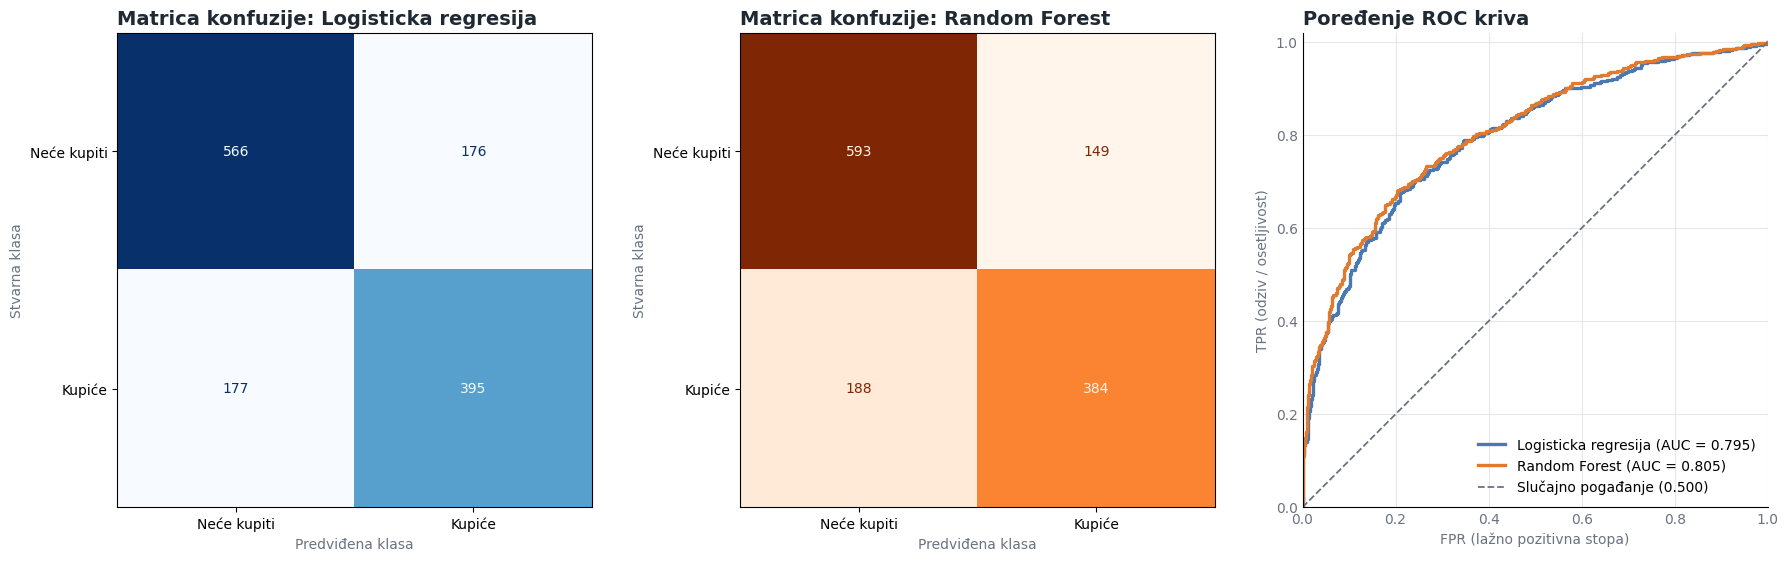

In [8]:
INK, MUTED, GRID = "#1f2933", "#6b7280", "#e5e7eb"

model_colors = {"Logisticka regresija": "#4a78b0", "Random Forest": "#e07a2f"}
model_cmaps  = {"Logisticka regresija": "Blues",   "Random Forest": "Oranges"}
labels = ["Neće kupiti", "Kupiće"]

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5), constrained_layout=True)

for ax, name in zip(axes[:2], ["Logisticka regresija", "Random Forest"]):
    cm = confusion_matrix(y_te, predictions[name])
    ConfusionMatrixDisplay(cm, display_labels=labels).plot(
        ax=ax, cmap=model_cmaps[name], colorbar=False, values_format="d")
    ax.set_title(f"Matrica konfuzije: {name}", loc="left",
                 fontsize=14, fontweight="bold", color=INK)
    ax.set_xlabel("Predviđena klasa", color=MUTED)
    ax.set_ylabel("Stvarna klasa", color=MUTED)
    ax.grid(False)

ax = axes[2]
for name in probs:
    if name == "Osnovna linija":
        continue
    fpr, tpr, _ = roc_curve(y_te, probs[name])
    auc = roc_auc_score(y_te, probs[name])
    ax.plot(fpr, tpr, linewidth=2.4, color=model_colors.get(name, "#2a9d8f"),
            label=f"{name} (AUC = {auc:.3f})")

ax.plot([0, 1], [0, 1], color=MUTED, linestyle="--", linewidth=1.3,
        label="Slučajno pogađanje (0.500)")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.set_aspect("equal", adjustable="box")
ax.set_xlabel("FPR (lažno pozitivna stopa)", color=MUTED)
ax.set_ylabel("TPR (odziv / osetljivost)", color=MUTED)
ax.set_title("Poređenje ROC kriva", loc="left", fontsize=14, fontweight="bold", color=INK)
ax.tick_params(colors=MUTED, length=0)
ax.set_axisbelow(True)
ax.grid(True, color=GRID, linewidth=0.8)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
ax.legend(frameon=False, loc="lower right")

plt.show()

# 5.5 Tumačenje modela i važnost osobina (*Feature Importance*)

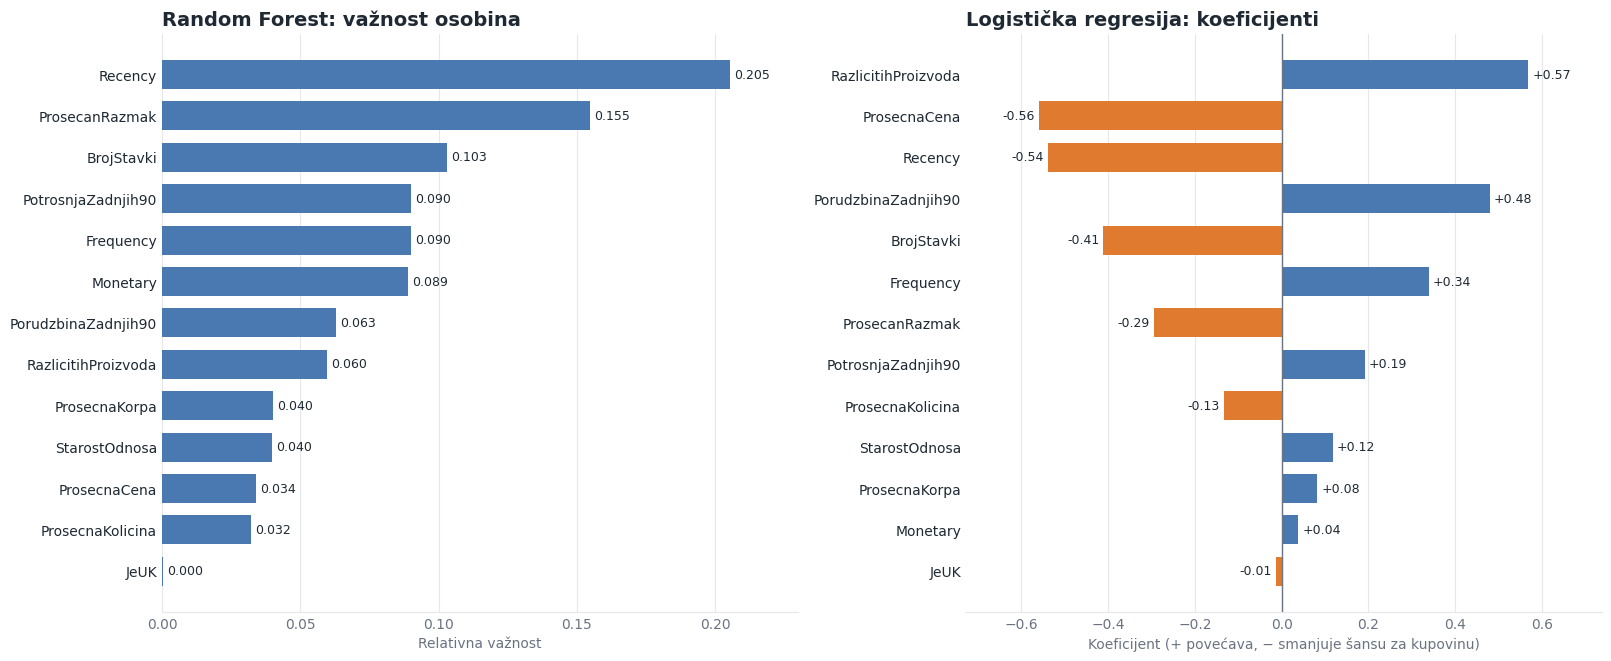

Top 5 najvažnijih osobina (Random Forest):
Recency               0.205
ProsecanRazmak        0.155
BrojStavki            0.103
PotrosnjaZadnjih90    0.090
Frequency             0.090
dtype: float64

Top 5 najutjecajnijih osobina (Logistička regresija, po |koeficijentu|):
RazlicitihProizvoda    0.568
ProsecnaCena          -0.559
Recency               -0.539
PorudzbinaZadnjih90    0.479
BrojStavki            -0.411
dtype: float64


In [9]:
INK, MUTED, GRID = "#1f2933", "#6b7280", "#e5e7eb"
BASE, ACCENT = "#4a78b0", "#e07a2f"

# Random Forest: važnost osobina (uvijek >= 0, zbir = 1)
rf_model = models["Random Forest"]
rf_importance = pd.Series(rf_model.feature_importances_, index=features).sort_values()

# Logistička regresija: koeficijenti (ako je Pipeline, uzimamo zadnji korak)
lr_model = models["Logisticka regresija"]
lr_clf = lr_model[-1] if hasattr(lr_model, "named_steps") else lr_model
lr_coef = pd.Series(lr_clf.coef_[0], index=features)
lr_coef = lr_coef.reindex(lr_coef.abs().sort_values().index)   # sortirano po apsolutnoj vrijednosti

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6.5), constrained_layout=True)

# 1. Random Forest
bars = ax1.barh(rf_importance.index, rf_importance.values, color=BASE, height=0.7)
ax1.bar_label(bars, fmt="%.3f", padding=3, fontsize=9, color=INK)
ax1.set_title("Random Forest: važnost osobina", loc="left",
              fontsize=14, fontweight="bold", color=INK)
ax1.set_xlabel("Relativna važnost", color=MUTED)
ax1.margins(x=0.12)

# 2. Logistička regresija (predznak je bitan: + povećava, - smanjuje šansu za kupovinu)
bar_colors = [BASE if v >= 0 else ACCENT for v in lr_coef.values]
bars = ax2.barh(lr_coef.index, lr_coef.values, color=bar_colors, height=0.7)
ax2.bar_label(bars, fmt="%+.2f", padding=3, fontsize=9, color=INK)
ax2.axvline(0, color=MUTED, linewidth=1)
ax2.set_title("Logistička regresija: koeficijenti", loc="left",
              fontsize=14, fontweight="bold", color=INK)
ax2.set_xlabel("Koeficijent (+ povećava, − smanjuje šansu za kupovinu)", color=MUTED)
ax2.margins(x=0.15)

for ax in (ax1, ax2):
    ax.tick_params(colors=MUTED, length=0)
    ax.tick_params(axis="y", labelcolor=INK, labelsize=10)
    ax.set_axisbelow(True)
    ax.xaxis.grid(True, color=GRID, linewidth=0.8)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(GRID)

plt.show()

print("Top 5 najvažnijih osobina (Random Forest):")
print(rf_importance.sort_values(ascending=False).head(5).round(3))

print("\nTop 5 najutjecajnijih osobina (Logistička regresija, po |koeficijentu|):")
print(lr_coef.reindex(lr_coef.abs().sort_values(ascending=False).index).head(5).round(3))

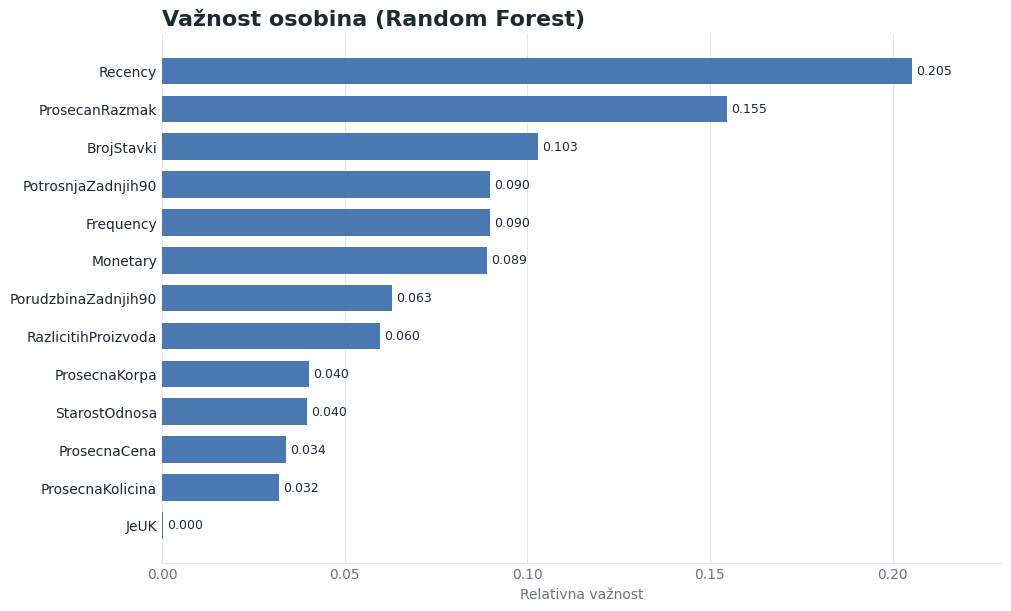

Top 5 najvažnijih osobina:
Recency               0.205
ProsecanRazmak        0.155
BrojStavki            0.103
PotrosnjaZadnjih90    0.090
Frequency             0.090
dtype: float64


In [10]:
INK, MUTED, GRID = "#1f2933", "#6b7280", "#e5e7eb"
BASE = "#4a78b0"

rf_model = models["Random Forest"]
importance = pd.Series(rf_model.feature_importances_, index=features).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(10, 6), constrained_layout=True)

bars = ax.barh(importance.index, importance.values, color=BASE, height=0.7)
ax.bar_label(bars, fmt="%.3f", padding=3, fontsize=9, color=INK)

ax.set_title("Važnost osobina (Random Forest)", loc="left",
             fontsize=16, fontweight="bold", color=INK)
ax.set_xlabel("Relativna važnost", color=MUTED)
ax.margins(x=0.12)

ax.tick_params(colors=MUTED, length=0)
ax.tick_params(axis="y", labelcolor=INK, labelsize=10)
ax.set_axisbelow(True)
ax.xaxis.grid(True, color=GRID, linewidth=0.8)
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color(GRID)

plt.show()

print("Top 5 najvažnijih osobina:")
print(importance.sort_values(ascending=False).head(5).round(3))

In [11]:
o.to_parquet("../data/podaci_model.parquet")

# Odgovori na pitanja — Dan 5

### Pitanje 5.1: Zašto je rezultat pokvarenog modela bezvredan?
Rezultat je bezvredan zbog **direktnog curenja ciljne promenljive (target leakage)**. Cilj je bio definisan kao `Recency <= 30`, a promenljiva `Recency` je istovremeno uključena kao prediktor! 
Model je jednostavno prepoznao identitet `Cilj = (Recency <= 30)`, što daje veštačku tačnost od 98% i AUC od 0,9998. Model ništa nije naučio o ponašanju kupaca i potpuno je neupotrebljiv za predviđanje budućih događaja.

### 1. Šta je curenje podataka i kako ste ga izbegli?
Curenje podataka (*data leakage*) nastaje kada model tokom treninga dobije pristup podacima iz budućnosti ili informacijama koje u trenutku primene modela u produkciji ne bi bile dostupne.
Izbegli smo ga implementacijom **strogog vremenskog preseka (*temporal cut-off*) na dan 2011-09-10**:
- Sve osobine (*features*) konstruisane su isključivo iz transakcija nastalih **pre datuma preseka**.
- Ciljna varijabla (*target*) formirana je isključivo na osnovu aktivnosti u periodu od 90 dana **nakon preseka**.

### 2. Osnovna linija ima tačnost 56,5%, a model ~74%. Da li je model dobar i zašto tačnost nije dovoljna?
Model je **veoma dobar**: nadmašio je naivnu liniju za skoro 18 procentnih poena u tačnosti i ostvario odličan **ROC AUC od 0,805**.
Tačnost nije dovoljna jer osnovna linija (predviđanje većinske klase da se kupac neće vratiti) ima 56,5% tačnosti a pronalazi **0% kupaca koji će se vratiti (Recall = 0%)**. Naš model ostvaruje balansiran odziv od 67,1% i preciznost od 72,0%, što znači da efikasno identifikuje 2 od 3 kupca koji se vraćaju.

### 3. Objasnite matricu konfuzije: lažna uzbuna vs propušten kupac. Koja greška je skuplja?
- **Lažna uzbuna (False Positive):** Model predvidi da će se kupac vratiti, a on ne kupi ništa.
- **Propušten kupac (False Negative):** Model predvidi da se kupac neće vratiti, a on bi došao (ili ga prepuštamo konkurenciji bez akcije).
Koja je greška skuplja zavisi od vrednosti podsticaja:
- Ako je podsticaj jeftin (npr. e-mail kampanja od par centi), **propušten kupac je neuporedivo skuplja greška** jer gubimo maržu i vrednost cele korpe (prosečno stotine funti).
- Ako je podsticaj skup (npr. vredan poklon paket ili lični odlazak komercijaliste na teren), lažna uzbuna generiše nepotreban direktan trošak.

### 4. `Recency` je najvažnija osobina. Da li je to isto curenje podataka kao u 5.1?
**Nije! Ovo je suštinska razlika.** 
U delu 5.1 `Recency` i cilj su mereni na istom skupu podataka i u istom vremenskom trenutku. U ispravnoj postavci (5.2), `Recency` meri koliko je dana proteklo od poslednje kupovine do datuma preseka — to je podatak koji menadžer regularno vidi na taj dan. Prirodno je da je kupac koji je kupovao pre 5 dana znatno skloniji povratku u naredna 3 meseca od kupca koji nije kupovao godinu dana. To je legitimna prediktivna moć istorijskog ponašanja, a ne curenje podataka.

### 5. Firma šalje kupon od 5 evra kupcima za koje model kaže da će se vratiti. Podići ili spustiti prag odlučivanja sa 0,5?
Ukoliko je cilj aktivacija i povećanje broja povratnika, a marža od prosečne korpe (£400) višestruko prevazilazi trošak kupona od 5 evra, firmi se isplati da **spusti prag odlučivanja** (npr. na 0,35–0,40) kako bi povećala odziv (*recall*) i obuhvatila više kupaca.
Međutim, ako šaljemo kupon onima koji bi se svakako vratili i bez kupona, dolazi do kanibalizacije profita. 
Da bismo tačno odredili optimalan prag, neophodni su nam:
1. Prosečna profitna marža po transakciji,
2. Inkrementalni efekat (*uplift*) — procenat kupaca koji kupuju *isključivo* zato što su dobili kupon,
3. Trošak distribucije i stopa iskorišćenja (*redemption rate*) kupona.
